# Kickstarter Campaign Success Analysis

**Goal:** identify the key factors that influence whether a Kickstarter campaign succeeds, using campaign-level data: category, country, funding goal, campaign duration and pledged amount.

**Dataset:** `Data/raw/Kickstarter.csv` - Kickstarter campaigns with metadata (category as JSON, country, timestamps, goal, pledged, state).

**Questions:**
1. What share of campaigns succeed?
2. Which categories perform best (and worst)?
3. How do goal size and campaign duration relate to success?
4. How do success rates differ by country, and by category within country?

## 1. Setup and data loading

In [1]:
# Core analysis libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Make sure the Images folder exists for the saved charts
import os
os.makedirs('Images', exist_ok=True)

In [2]:
# Load the raw campaign data (relative path, so the notebook runs from the repo root)
df = pd.read_csv('Data/raw/Kickstarter.csv')
print(df.shape)
df.head()

(3194, 42)


,backers_count,blurb,category,converted_pledged_amount,country,country_displayable_name,created_at,creator,currency,currency_symbol,...,spotlight,staff_pick,state,state_changed_at,static_usd_rate,urls,usd_exchange_rate,usd_pledged,usd_type,video
0,2,"Nature's Bounty Farm, Inc is a non profit orga...","{""id"":305,""name"":""Community Gardens"",""analytic...",65.0,US,the United States,1477586619,"{""id"":1511805759,""name"":""Tabatha Tasker"",""is_r...",USD,$,...,False,False,failed,1480959781,1.0,"{""web"":{""project"":""https://www.kickstarter.com...",1.0,65.0,domestic,"{""id"":720778,""status"":""successful"",""hls"":null,..."
1,2,Ubuntu Cultivators is dedicated to growing yea...,"{""id"":305,""name"":""Community Gardens"",""analytic...",101.0,US,the United States,1474041806,"{""id"":1676618956,""name"":""Hannah Kiraly"",""is_re...",USD,$,...,False,False,failed,1479492461,1.0,"{""web"":{""project"":""https://www.kickstarter.com...",1.0,101.0,domestic,NaN
2,12,He accidentally got her fired. Then he stole h...,"{""id"":47,""name"":""Fiction"",""analytics_name"":""Fi...",222.0,US,the United States,1735658350,"{""id"":529770689,""name"":""Kathryn Kaleigh"",""slug...",USD,$,...,False,False,live,1736267868,1.0,"{""web"":{""project"":""https://www.kickstarter.com...",1.0,222.0,domestic,NaN
3,40,"Printing Chapters 1-2 of my webcomic, Lanterns...","{""id"":253,""name"":""Webcomics"",""analytics_name"":...",1217.0,US,the United States,1565130202,"{""id"":1425061218,""name"":""spaceturtleart"",""slug...",USD,$,...,False,False,failed,1570120062,1.0,"{""web"":{""project"":""https://www.kickstarter.com...",1.0,1217.0,domestic,"{""id"":982781,""status"":""successful"",""hls"":""http..."
4,4,Scoffer Studios Productions is an indie studio...,"{""id"":253,""name"":""Webcomics"",""analytics_name"":...",42.0,US,the United States,1557876684,"{""id"":515139000,""name"":""Gov Scoffer"",""is_regis...",USD,$,...,False,False,failed,1561862339,1.0,"{""web"":{""project"":""https://www.kickstarter.com...",1.0,42.0,domestic,NaN


## 2. Data cleaning

All cleaning happens up front so every analysis below uses the same clean dataset:
1. Drop exact duplicate rows.
2. Drop rows missing the fields we analyze (`goal`, `pledged`, `state`).
3. Convert UNIX timestamps to datetimes.
4. Keep only finished campaigns (`successful` / `failed`) - live, canceled and suspended campaigns have no outcome to analyze.
5. Remove invalid values (goal <= 0, negative pledged) and outlier goals above the 99th percentile, so a few extreme campaigns don't skew averages.

In [3]:
# Quick profile: column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3194 entries, 0 to 3193
Data columns (total 42 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   backers_count                       3194 non-null   int64  
 1   blurb                               3194 non-null   object 
 2   category                            3194 non-null   object 
 3   converted_pledged_amount            2969 non-null   float64
 4   country                             3194 non-null   object 
 5   country_displayable_name            3194 non-null   object 
 6   created_at                          3194 non-null   int64  
 7   creator                             3194 non-null   object 
 8   currency                            3194 non-null   object 
 9   currency_symbol                     3194 non-null   object 
 10  currency_trailing_code              3194 non-null   bool   
 11  current_currency                    3194 no

In [4]:
# How many missing values does each column have?
df.isnull().sum()

backers_count                            0
blurb                                    0
category                                 0
converted_pledged_amount               225
country                                  0
country_displayable_name                 0
created_at                               0
creator                                  0
currency                                 0
currency_symbol                          0
currency_trailing_code                   0
current_currency                         0
deadline                                 0
disable_communication                    0
fx_rate                                  0
goal                                     0
id                                       0
is_disliked                              0
is_in_post_campaign_pledging_phase    2507
is_launched                              0
is_liked                                 0
is_starrable                             0
launched_at                              0
location   

In [5]:
# 1. Drop exact duplicate rows
df = df.drop_duplicates()

# 2. Drop rows that are missing the fields we analyze
df = df.dropna(subset=['goal', 'pledged', 'state'])

In [6]:
# 3. Convert UNIX timestamps (seconds) into usable datetimes
df['launched_at'] = pd.to_datetime(df['launched_at'], unit='s', errors='coerce')
df['deadline'] = pd.to_datetime(df['deadline'], unit='s', errors='coerce')
df['created_at'] = pd.to_datetime(df['created_at'], unit='s', errors='coerce')
df['state_changed_at'] = pd.to_datetime(df['state_changed_at'], unit='s', errors='coerce')

In [7]:
# 4. Keep only campaigns that finished with a clear outcome
df = df[df['state'].isin(['successful', 'failed'])]

In [8]:
# 5. Remove invalid values and outlier goals (top 1%)
df = df[df['goal'] > 0]
df = df[df['pledged'] >= 0]
df = df[df['goal'] < df['goal'].quantile(0.99)]
print(f"Clean dataset: {df.shape[0]} campaigns")

Clean dataset: 2735 campaigns


In [9]:
# The category column is a JSON string - parse out the human-readable category name.
# Parse failures are counted instead of silently ignored, so we know if data quality is an issue.
parse_failures = 0

def extract_category(x):
    try:
        return json.loads(x)['name']
    except (json.JSONDecodeError, KeyError, TypeError):
        global parse_failures
        parse_failures += 1
        return None

df['main_category'] = df['category'].apply(extract_category)
print(f"Category parse failures: {parse_failures}")

Category parse failures: 0


## 3. Feature engineering

Create the three derived fields used across the analysis:
- `duration_days` - campaign length in days (deadline minus launch).
- `is_successful` - 1 for successful campaigns, 0 for failed.
- `funding_ratio` - pledged amount divided by goal (>1 means overfunded).

In [10]:
# Campaign length in days
df['duration_days'] = ((df['deadline'] - df['launched_at']).dt.total_seconds() / 86400).round()
df['duration_days'][:5]

0    31.0
1    60.0
3    30.0
4    40.0
5    30.0
Name: duration_days, dtype: float64

In [11]:
# Success flag: 1 if the campaign reached its goal, 0 otherwise
df['is_successful'] = df['state'].apply(lambda x: 1 if x == 'successful' else 0)
df['is_successful'][:5]

0    0
1    0
3    0
4    0
5    0
Name: is_successful, dtype: int64

In [12]:
# Funding ratio: how much of the goal was actually pledged
df['funding_ratio'] = df['pledged'] / df['goal']
df['funding_ratio'][:5]

0    0.000433
1    0.010100
3    0.093615
4    0.420000
5    0.160000
Name: funding_ratio, dtype: float64

## 4. Overall success rate

In [13]:
# Share of successful vs failed campaigns
df['state'].value_counts(normalize=True)

state
successful    0.670932
failed        0.329068
Name: proportion, dtype: float64

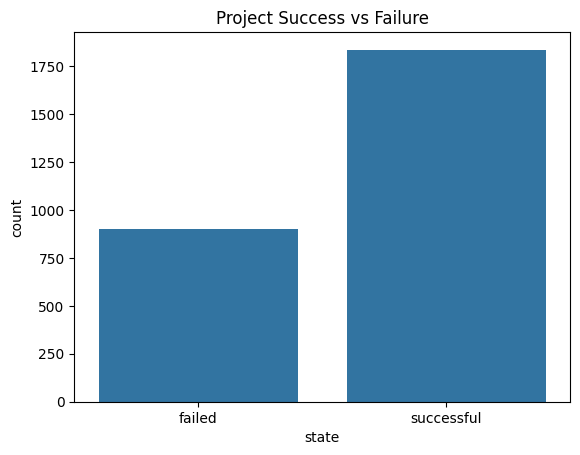

In [14]:
# Chart: successful vs failed campaign counts
sns.countplot(x='state', data=df)
plt.title("Project Success vs Failure")
plt.savefig('Images/Project-Success-vs-Failure-ratio.png', bbox_inches='tight')
plt.show()

**Takeaway:** about 67% of finished campaigns in this dataset reach their goal; roughly 1 in 3 fails.

## 5. Success rate by category

Categories with very few campaigns give misleading rates, so only categories with more than 50 campaigns are compared.

In [15]:
# Count campaigns per category and keep only categories with more than 50 campaigns
category_count = df['main_category'].value_counts()
valid_categories = category_count[category_count > 50].index
df_filtered = df[df['main_category'].isin(valid_categories)]
print(f"{len(valid_categories)} categories with 50+ campaigns")

13 categories with 50+ campaigns


In [16]:
# Average success rate per category, highest first
df_filtered.groupby('main_category')['is_successful'].mean().sort_values(ascending=False)

main_category
Accessories         1.000000
Art Books           1.000000
Comic Books         1.000000
Drama               1.000000
Gadgets             1.000000
Hardware            1.000000
Indie Rock          1.000000
Mixed Media         1.000000
Radio & Podcasts    0.531915
Stationery          0.490909
Ready-to-wear       0.467742
Small Batch         0.139535
Web                 0.086022
Name: is_successful, dtype: float64

**Takeaway:** several categories (Hardware, Drama, Comic Books, Mixed Media and others) show a 100% success rate - but each has a small campaign count, so treat those with care. The weakest categories are Web (~9% success) and Small Batch (~14%).

## 6. Goal size and campaign duration vs success

In [17]:
# Split campaigns into 5 goal-size groups (quintiles) and compare success rates
df.groupby(pd.qcut(df['goal'], q=5, duplicates='drop'))['is_successful'].mean()

/tmp/ipykernel_2353/3346848161.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(pd.qcut(df['goal'], q=5, duplicates='drop'))['is_successful'].mean()


goal
(0.999, 1000.0]        0.793600
(1000.0, 3000.0]       0.723757
(3000.0, 6285.0]       0.708245
(6285.0, 15000.0]      0.628319
(15000.0, 278500.0]    0.483932
Name: is_successful, dtype: float64

In [18]:
# Same comparison for campaign length
df.groupby(pd.qcut(df['duration_days'], q=5, duplicates='drop'))['is_successful'].mean()

/tmp/ipykernel_2353/2283518545.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(pd.qcut(df['duration_days'], q=5, duplicates='drop'))['is_successful'].mean()


duration_days
(0.999, 27.0]    0.797101
(27.0, 30.0]     0.651925
(30.0, 43.0]     0.737470
(43.0, 90.0]     0.534070
Name: is_successful, dtype: float64

**Takeaway:** smaller goals succeed far more often - campaigns asking up to $1,000 succeed ~79% of the time, versus ~48% for goals above $15,000. Very short campaigns (up to 27 days) also perform best (~80% success), while campaigns running 43-90 days succeed only ~53% of the time.

## 7. Success rate by country

In [19]:
# Average success rate per country, highest first
country_success = df.groupby('country')['is_successful'].mean().sort_values(ascending=False)
country_success

country
LU    1.000000
HK    0.916667
NZ    0.800000
SG    0.750000
GB    0.743003
US    0.679472
CA    0.671875
JP    0.625000
AU    0.600000
NO    0.600000
MX    0.586957
BE    0.583333
ES    0.578947
FR    0.545455
IT    0.520000
DE    0.517241
NL    0.500000
SE    0.454545
DK    0.428571
IE    0.400000
GR    0.250000
AT    0.250000
PL    0.200000
CH    0.166667
Name: is_successful, dtype: float64

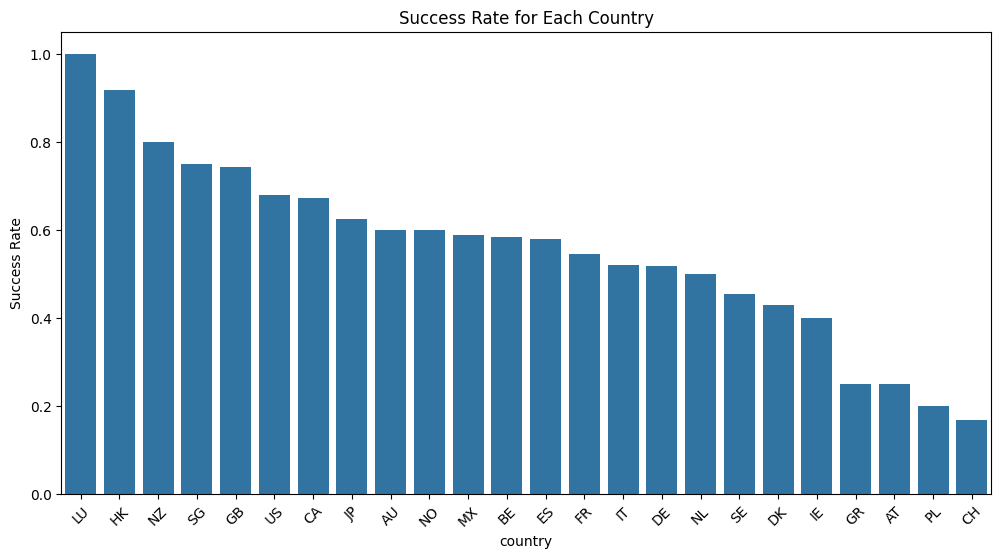

In [20]:
# Chart: success rate for each country
plt.figure(figsize=(12, 6))
sns.barplot(x=country_success.index, y=country_success.values)
plt.xticks(rotation=45)
plt.ylabel('Success Rate')
plt.title('Success Rate for Each Country')
plt.savefig('Images/Success-rate-for-each-Country.png', bbox_inches='tight')
plt.show()

**Takeaway:** the US dominates campaign volume and succeeds ~68% of the time. Some smaller markets (Luxembourg, Hong Kong, New Zealand) show higher rates but on very few campaigns.

## 8. Category performance by country

In [21]:
# Take the top 10 categories by total number of campaigns
top_categories = df['main_category'].value_counts().nlargest(10).index
df_top = df[df['main_category'].isin(top_categories)]

In [22]:
# ... and the top 10 countries by campaign volume
top_countries = df['country'].value_counts().nlargest(10).index
df_top = df_top[df_top['country'].isin(top_countries)]

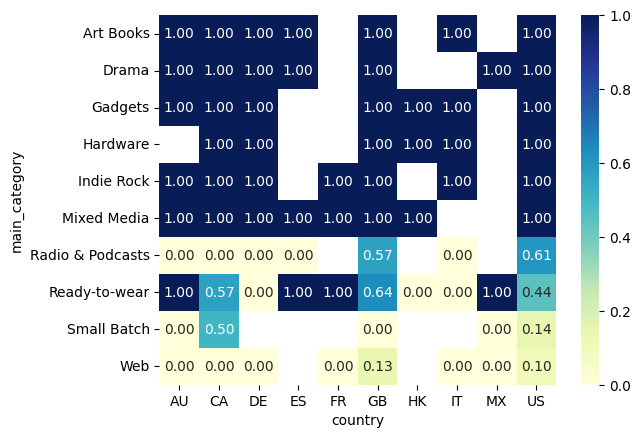

In [23]:
# Heatmap: average success rate for each top category in each top country
pivot = df_top.pivot_table(index='main_category', columns='country', values='is_successful', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt=".2f", cmap='YlGnBu')
plt.savefig('Images/Category-Success-rate-for-each-Country.png', bbox_inches='tight')
plt.show()

**Takeaway:** categories do not perform equally across countries - a category that is strong in one market can be weak in another, which matters when choosing where to launch.

## 9. Largest funded campaign per country and category

In [24]:
# Highest pledged amount for each country-category combination
category_country_max_funding = df.groupby(['country', 'main_category'])['pledged'].max().reset_index()
category_country_max_funding.sort_values(by=['pledged', 'main_category'], ascending=False)

,country,main_category,pledged
518,US,Hardware,5394102.0
312,HK,Hardware,3288056.0
554,US,Ready-to-wear,3127299.5
320,HK,Sound,2683242.0
367,JP,Apparel,2500309.0
...,...,...,...
383,MX,Food Trucks,0.0
407,NL,Food Trucks,0.0
405,NL,DIY,0.0
1,AT,Camera Equipment,0.0


**Takeaway:** this shows the single best-funded campaign per country-category pair. It is driven by individual outlier hits, so it is useful for spotting blockbuster campaigns rather than typical performance (typical performance is the success-rate view above).

## 10. Conclusions

- About 67% of finished campaigns succeed.
- Goal size is the clearest success factor: modest goals (up to ~$1,000) succeed ~79% of the time; goals above ~$15,000 succeed less than half the time.
- Shorter campaigns (up to ~27 days) outperform long ones (43-90 days succeed ~53%).
- Category matters, and category strength varies by country; some 100%-success categories rest on very few campaigns.
- The US dominates both campaign volume and total funding.

**Limitations:** several category and country rates are based on small samples; the dataset may not represent all Kickstarter campaigns; this is descriptive EDA, so the findings are associations, not causal effects.